In [376]:
import pandas as pd
import seaborn as sns
import numpy as np
from rdkit import Chem
from rdkit.Chem import PeriodicTable
from rdkit.Chem import AllChem
from rdkit.Chem import rdFingerprintGenerator as rdf
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import keras
from collections import defaultdict
from rdkit.Chem.rdPartialCharges import ComputeGasteigerCharges
from sklearn.model_selection import train_test_split
from rdkit.Chem import Descriptors
import nglview as nv
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import seaborn as sns

In [377]:
df_new = pd.read_csv('ChemAI-papers.csv')
df_new['new'] = True
df_new.drop(columns = 'paper', inplace = True)

In [378]:
df = pd.read_csv('CH_borylation_ChemAI_assessment.csv')
df['new'] = False
df

,rxn_id,substrate_smiles,substrate_smiles_mapped,temperature_degC,solvent_1_smiles,solvent_1_fraction,solvent_2_smiles,solvent_2_fraction,catalyst_1_smiles,catalyst_2_smiles,...,reagent_3_smiles,reagent_4_smiles,total_yield,product_smiles,product_smiles_mapped,site,yield,regio_fraction,source_DOI,new
0,lit_pub_bo_1075,COc1cccc(OC)c1OC,[CH3:1][O:2][c:3]1[cH:4][cH:5][cH:6][c:7]([O:8...,80,O1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,0.74,COc1cc(B2OC(C)(C)C(C)(C)O2)cc(OC)c1OC,[CH3:1][O:2][c:3]1[cH:4][c:5]([B:6]2[O:7][C:8]...,5,0.74,1.000000,10.1021/ja400295v,False
1,lit_pub_bo_109,CN(C)c1ccccc1,[CH3:1][N:2]([CH3:3])[c:4]1[cH:5][cH:6][cH:7][...,100,ClC=1C=CC=CC1Cl,1.0,NaN,NaN,FC=1C(F)=C(F)C(B(C=2C(F)=C(F)C(F)=C(F)C2F)C=3C...,NaN,...,OC(C)(C)C(O)(C)C,NaN,0.98,CN(C)c1ccc(B2OC(C)(C)C(C)(C)O2)cc1,[CH3:1][N:2]([CH3:3])[c:4]1[cH:5][cH:6][c:7]([...,7,0.98,1.000000,10.1002/anie.201611536,False
2,lit_pub_bo_1125,Cc1cccc(Br)c1,[CH3:1][c:2]1[cH:3][cH:4][cH:5][c:6]([Br:7])[c...,25,N(CC)(CC)CC,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,0.35,Cc1cc(Br)cc(B2OC(C)(C)C(C)(C)O2)c1,[CH3:1][c:2]1[cH:3][c:4]([Br:5])[cH:6][c:7]([B...,4,0.35,1.000000,10.1021/ja400295v,False
3,lit_pub_bo_114,c1ccc(N2CCCC2)cc1,[cH:1]1[cH:2][cH:3][c:4]([N:5]2[CH2:6][CH2:7][...,120,C=1C=CC(=CC1)C,1.0,NaN,NaN,FC=1C(F)=C(F)C(B(C=2C(F)=C(F)C(F)=C(F)C2F)C=3C...,NaN,...,OC(C)(C)C(O)(C)C,NaN,0.92,CC1(C)OB(c2ccc(N3CCCC3)cc2)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,1,0.92,1.000000,10.1002/anie.201611536,False
4,lit_pub_bo_115,CN(c1ccccc1)c1ccccc1,[CH3:1][N:2]([c:3]1[cH:4][cH:5][cH:6][cH:7][cH...,120,C=1C=CC(=CC1)C,1.0,NaN,NaN,FC=1C(F)=C(F)C(B(C=2C(F)=C(F)C(F)=C(F)C2F)C=3C...,NaN,...,OC(C)(C)C(O)(C)C,NaN,0.35,CN(c1ccccc1)c1ccc(B2OC(C)(C)C(C)(C)O2)cc1,[CH3:1][N:2]([c:3]1[cH:4][cH:5][cH:6][cH:7][cH...,12,0.35,1.000000,10.1002/anie.201611536,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
739,lit_pub_bo_992,CC(C)(C)OC(=O)Nc1ccc(Cl)c(F)c1,[CH3:1][C:2]([CH3:3])([CH3:4])[O:5][C:6](=[O:7...,50,O(C)C(C)(C)C,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,0.68,CC(C)(C)OC(=O)Nc1cc(F)c(Cl)cc1B1OC(C)(C)C(C)(C)O1,[CH3:1][C:2]([CH3:3])([CH3:4])[O:5][C:6](=[O:7...,10,0.52,0.764706,10.1021/ja303443m,False
740,lit_pub_bo_992,CC(C)(C)OC(=O)Nc1ccc(Cl)c(F)c1,[CH3:1][C:2]([CH3:3])([CH3:4])[O:5][C:6](=[O:7...,50,O(C)C(C)(C)C,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,0.68,CC(C)(C)OC(=O)Nc1ccc(Cl)c(F)c1B1OC(C)(C)C(C)(C)O1,[CH3:1][C:2]([CH3:3])([CH3:4])[O:5][C:6](=[O:7...,16,0.16,0.235294,10.1021/ja303443m,False
741,lit_pub_bo_993,COc1c(C)cccc1C,[CH3:1][O:2][c:3]1[c:4]([CH3:5])[cH:6][cH:7][c...,80,O1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,0.88,COc1c(C)cc(B2OC(C)(C)C(C)(C)O2)cc1C,[CH3:1][O:2][c:3]1[c:4]([CH3:5])[cH:6][c:7]([B...,7,0.88,1.000000,10.1021/ja400295v,False
742,lit_pub_bo_994,COc1cccc(OC)c1,[CH3:1][O:2][c:3]1[cH:4][cH:5][cH:6][c:7]([O:8...,80,O1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,0.82,COc1cc(OC)cc(B2OC(C)(C)C(C)(C)O2)c1,[CH3:1][O:2][c:3]1[cH:4][c:5]([O:6][CH3:7])[cH...,5,0.82,1.000000,10.1021/ja400295v,False


In [379]:
df = pd.concat([df, df_new], ignore_index=True)
df.sort_values(by='substrate_smiles_mapped', ascending=True, inplace=True)
df

,rxn_id,substrate_smiles,substrate_smiles_mapped,temperature_degC,solvent_1_smiles,solvent_1_fraction,solvent_2_smiles,solvent_2_fraction,catalyst_1_smiles,catalyst_2_smiles,...,reagent_3_smiles,reagent_4_smiles,total_yield,product_smiles,product_smiles_mapped,site,yield,regio_fraction,source_DOI,new
155,lit_pub_bo_222,Brc1ccc(Br)cc1,[Br:1][c:2]1[cH:3][cH:4][c:5]([Br:6])[cH:7][cH...,100,O(C)C1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,0.62,CC1(C)OB(c2cc(Br)ccc2Br)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,4,0.62,1.000000,10.1021/jacs.5b05252,False
181,lit_pub_bo_27,Brc1ccc2[nH]ccc2c1,[Br:1][c:2]1[cH:3][cH:4][c:5]2[nH:6][cH:7][cH:...,80,O1CCCC1,1.0,NaN,NaN,[Cl-]1[Ir+]234([Cl-][Ir+]1567[CH]=8CC[CH]7=[CH...,NaN,...,NaN,NaN,0.55,CC1(C)OB(c2cc(Br)cc3cc[nH]c23)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,4,0.55,1.000000,10.1021/ja1006405,False
138,lit_pub_bo_206,Brc1cccc(Br)c1,[Br:1][c:2]1[cH:3][cH:4][cH:5][c:6]([Br:7])[cH...,100,O(C)C1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,0.98,CC1(C)OB(c2cc(Br)cc(Br)c2)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,4,0.98,1.000000,10.1021/jacs.5b05252,False
139,lit_pub_bo_207,Brc1ccccc1Br,[Br:1][c:2]1[cH:3][cH:4][cH:5][cH:6][c:7]1[Br:8],80,O(C)C1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,0.98,CC1(C)OB(c2ccc(Br)c(Br)c2)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,5,0.98,1.000000,10.1021/jacs.5b05252,False
149,lit_pub_bo_216,Brc1cccs1,[Br:1][c:2]1[cH:3][cH:4][cH:5][s:6]1,100,O(C)C1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,0.96,CC1(C)OB(c2ccc(Br)s2)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,5,0.96,1.000000,10.1021/jacs.5b05252,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
177,lit_pub_bo_247,c1ccc2sccc2c1,[cH:1]1[cH:2][cH:3][c:4]2[s:5][cH:6][cH:7][c:8...,100,CCCCCCC,1.0,NaN,NaN,O1[Si](C)(C)[CH]2=[CH2][Pt+2]32(=[C-2]4N(C=CN4...,NaN,...,NaN,NaN,0.44,CC1(C)OB(c2csc3ccccc23)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,7,0.04,0.090909,10.1021/jacs.5b07677,False
176,lit_pub_bo_247,c1ccc2sccc2c1,[cH:1]1[cH:2][cH:3][c:4]2[s:5][cH:6][cH:7][c:8...,100,CCCCCCC,1.0,NaN,NaN,O1[Si](C)(C)[CH]2=[CH2][Pt+2]32(=[C-2]4N(C=CN4...,NaN,...,NaN,NaN,0.44,CC1(C)OB(c2cc3ccccc3s2)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,6,0.40,0.909091,10.1021/jacs.5b07677,False
596,lit_pub_bo_76,c1cnc2[nH]ccc2c1,[cH:1]1[cH:2][n:3][c:4]2[nH:5][cH:6][cH:7][c:8...,80,O1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,0.55,CC1(C)OB(c2c[nH]c3ncccc23)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,7,0.55,1.000000,10.1021/ja412563e,False
540,lit_pub_bo_70,c1cn[nH]c1,[cH:1]1[cH:2][n:3][nH:4][cH:5]1,80,O1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,0.56,CC1(C)OB(c2cn[nH]c2)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,1,0.56,1.000000,10.1021/ja412563e,False


In [380]:
print(f'Number of entries before dropping the duplicates: {len(df)}')
df.drop_duplicates(inplace=True)
print(f'Number of entries after dropping the duplicates: {len(df)}')

Number of entries before dropping the duplicates: 755
Number of entries after dropping the duplicates: 754


In [381]:
print(f'Number of unique smiles: {df['substrate_smiles'].nunique()}')
print(f'Number of unique reactions: {df['rxn_id'].nunique()}')

Number of unique smiles: 638
Number of unique reactions: 638


In [382]:
df['rxn_id'].nunique()

638

In [383]:
df['temperature_degC'].replace('50-60', 55, inplace=True)

/var/folders/xl/v8lcvy855_39wt1534xvs_hw0000gn/T/ipykernel_43035/4233582209.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['temperature_degC'].replace('50-60', 55, inplace=True)


In [384]:
from scipy.special import expit, logit
from scipy.stats import norm, rankdata

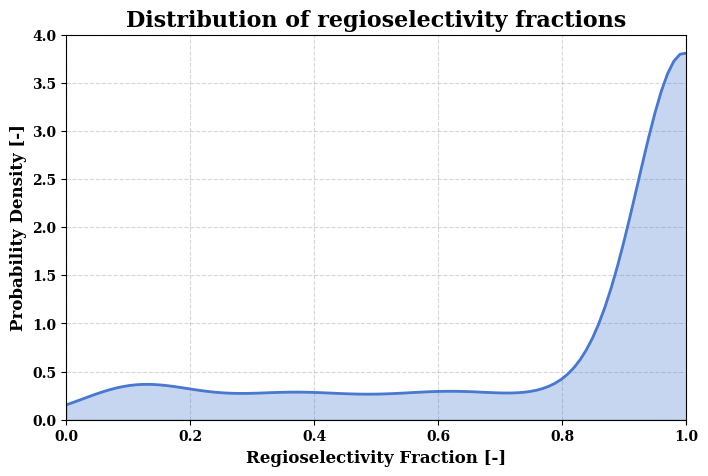

In [385]:
regio_fractions = df['regio_fraction']
kde = gaussian_kde(regio_fractions)

x = np.linspace(0, 1, 100)
y = kde(x)

palette = sns.color_palette('muted')
fig, ax = plt.subplots(ncols = 1, figsize=(8, 5))

ax.plot(x,y, color=palette[0], lw = 2)
ax.fill_between(x, y, color=palette[0], alpha=0.3)
ax.set_xlim(0, 1)
ax.set_ylim(0, 4)
ax.set_xlabel('Regioselectivity Fraction [-]', fontsize=12, fontweight='bold', family='serif')
ax.set_ylabel('Probability Density [-]', fontsize = 12, fontweight='bold', family='serif')
ax.set_title('Distribution of regioselectivity fractions', fontsize=16, fontweight='bold', family='serif')

ax.set_axisbelow(True)
ax.grid(alpha=0.5, ls='--')

for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontfamily('serif')
    label.set_fontweight('bold')

plt.savefig('regioselectivity_distribution.png', dpi=500, bbox_inches='tight')

In [386]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 754 entries, 155 to 209
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   rxn_id                   754 non-null    object 
 1   substrate_smiles         754 non-null    object 
 2   substrate_smiles_mapped  754 non-null    object 
 3   temperature_degC         754 non-null    object 
 4   solvent_1_smiles         745 non-null    object 
 5   solvent_1_fraction       736 non-null    float64
 6   solvent_2_smiles         89 non-null     object 
 7   solvent_2_fraction       88 non-null     float64
 8   catalyst_1_smiles        698 non-null    object 
 9   catalyst_2_smiles        53 non-null     object 
 10  ligand_1_smiles          627 non-null    object 
 11  ligand_2_smiles          19 non-null     object 
 12  additive_1_smiles        154 non-null    object 
 13  reagent_1_smiles         754 non-null    object 
 14  reagent_2_smiles         287 

In [387]:
df.describe()

,solvent_1_fraction,solvent_2_fraction,total_yield,site,yield,regio_fraction
count,736.000000,88.000000,754.000000,754.000000,754.000000,754.000000
mean,0.948914,0.427261,0.743528,9.718833,0.620239,0.845645
std,0.160530,0.234816,0.166903,5.789856,0.248098,0.283908
min,0.000000,0.000000,0.310000,1.000000,0.010000,0.021505
25%,1.000000,0.200000,0.630000,6.000000,0.470000,0.841356
50%,1.000000,0.450000,0.760000,9.000000,0.660000,1.000000
75%,1.000000,0.450000,0.880000,12.000000,0.810000,1.000000
max,1.000000,1.000000,1.000000,33.000000,1.000000,1.000000


array([[<Axes: title={'center': 'solvent_1_fraction'}>,
        <Axes: title={'center': 'solvent_2_fraction'}>,
        <Axes: title={'center': 'total_yield'}>],
       [<Axes: title={'center': 'site'}>,
        <Axes: title={'center': 'yield'}>,
        <Axes: title={'center': 'regio_fraction'}>]], dtype=object)

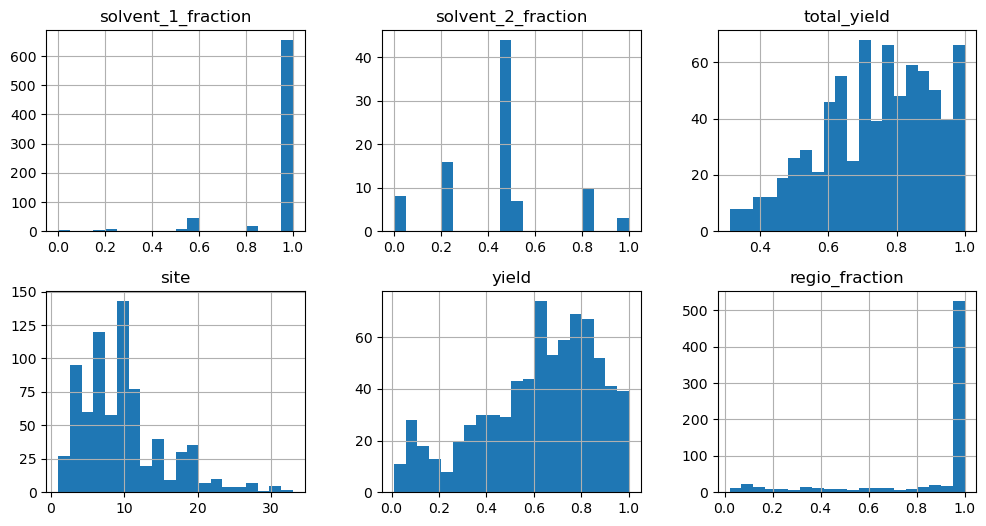

In [388]:
df.hist(bins = 20,layout=[2,3], figsize=[12,6])

In [389]:
substrate_maps = {
    substrate: dict(zip(g['site'].astype(int), g['regio_fraction']))
    for substrate, g in df.groupby('substrate_smiles_mapped')
}

In [390]:
df.drop(columns=['regio_fraction', 'total_yield'], inplace=True)

In [391]:
df.drop_duplicates(inplace=True, subset=['substrate_smiles_mapped'])
df.reset_index(inplace=True, drop = True)
print(len(df))

638


In [392]:
df['reactivity_map'] = df['substrate_smiles_mapped'].map(substrate_maps)

In [393]:
df

,rxn_id,substrate_smiles,substrate_smiles_mapped,temperature_degC,solvent_1_smiles,solvent_1_fraction,solvent_2_smiles,solvent_2_fraction,catalyst_1_smiles,catalyst_2_smiles,...,reagent_2_smiles,reagent_3_smiles,reagent_4_smiles,product_smiles,product_smiles_mapped,site,yield,source_DOI,new,reactivity_map
0,lit_pub_bo_222,Brc1ccc(Br)cc1,[Br:1][c:2]1[cH:3][cH:4][c:5]([Br:6])[cH:7][cH...,100,O(C)C1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,NaN,CC1(C)OB(c2cc(Br)ccc2Br)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,4,0.62,10.1021/jacs.5b05252,False,{4: 1.0}
1,lit_pub_bo_27,Brc1ccc2[nH]ccc2c1,[Br:1][c:2]1[cH:3][cH:4][c:5]2[nH:6][cH:7][cH:...,80,O1CCCC1,1.0,NaN,NaN,[Cl-]1[Ir+]234([Cl-][Ir+]1567[CH]=8CC[CH]7=[CH...,NaN,...,O1BOC(C)(C)C1(C)C,NaN,NaN,CC1(C)OB(c2cc(Br)cc3cc[nH]c23)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,4,0.55,10.1021/ja1006405,False,{4: 1.0}
2,lit_pub_bo_206,Brc1cccc(Br)c1,[Br:1][c:2]1[cH:3][cH:4][cH:5][c:6]([Br:7])[cH...,100,O(C)C1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,NaN,CC1(C)OB(c2cc(Br)cc(Br)c2)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,4,0.98,10.1021/jacs.5b05252,False,{4: 1.0}
3,lit_pub_bo_207,Brc1ccccc1Br,[Br:1][c:2]1[cH:3][cH:4][cH:5][cH:6][c:7]1[Br:8],80,O(C)C1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,NaN,CC1(C)OB(c2ccc(Br)c(Br)c2)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,5,0.98,10.1021/jacs.5b05252,False,{5: 1.0}
4,lit_pub_bo_216,Brc1cccs1,[Br:1][c:2]1[cH:3][cH:4][cH:5][s:6]1,100,O(C)C1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,NaN,CC1(C)OB(c2ccc(Br)s2)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,5,0.96,10.1021/jacs.5b05252,False,{5: 1.0}
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
633,lit_pub_bo_248,c1ccc2occc2c1,[cH:1]1[cH:2][cH:3][c:4]2[o:5][cH:6][cH:7][c:8...,100,CCCCCCC,1.0,NaN,NaN,O1[Si](C)(C)[CH]2=[CH2][Pt+2]32(=[C-2]4N(C=CN4...,NaN,...,NaN,NaN,NaN,CC1(C)OB(c2cc3ccccc3o2)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,6,0.35,10.1021/jacs.5b07677,False,"{6: 0.7446808510638298, 7: 0.2553191489361702}"
634,lit_pub_bo_247,c1ccc2sccc2c1,[cH:1]1[cH:2][cH:3][c:4]2[s:5][cH:6][cH:7][c:8...,100,CCCCCCC,1.0,NaN,NaN,O1[Si](C)(C)[CH]2=[CH2][Pt+2]32(=[C-2]4N(C=CN4...,NaN,...,NaN,NaN,NaN,CC1(C)OB(c2csc3ccccc23)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,7,0.04,10.1021/jacs.5b07677,False,"{7: 0.0909090909090909, 6: 0.9090909090909092}"
635,lit_pub_bo_76,c1cnc2[nH]ccc2c1,[cH:1]1[cH:2][n:3][c:4]2[nH:5][cH:6][cH:7][c:8...,80,O1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,NaN,CC1(C)OB(c2c[nH]c3ncccc23)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,7,0.55,10.1021/ja412563e,False,{7: 1.0}
636,lit_pub_bo_70,c1cn[nH]c1,[cH:1]1[cH:2][n:3][nH:4][cH:5]1,80,O1CCCC1,1.0,NaN,NaN,[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...,NaN,...,NaN,NaN,NaN,CC1(C)OB(c2cn[nH]c2)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,1,0.56,10.1021/ja412563e,False,{1: 1.0}


In [394]:
df.loc[0]

rxn_id                                                        lit_pub_bo_222
substrate_smiles                                              Brc1ccc(Br)cc1
substrate_smiles_mapped    [Br:1][c:2]1[cH:3][cH:4][c:5]([Br:6])[cH:7][cH...
temperature_degC                                                         100
solvent_1_smiles                                                 O(C)C1CCCC1
solvent_1_fraction                                                       1.0
solvent_2_smiles                                                         NaN
solvent_2_fraction                                                       NaN
catalyst_1_smiles          [O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7...
catalyst_2_smiles                                                        NaN
ligand_1_smiles            N=1C=CC=CC1N2B(NC=3C=CC=CC32)B4NC=5C=CC=CC5N4C...
ligand_2_smiles                                                          NaN
additive_1_smiles                                                        NaN

In [395]:
df.describe()

,solvent_1_fraction,solvent_2_fraction,site,yield
count,621.000000,87.000000,638.000000,638.000000
mean,0.939454,0.432172,9.780564,0.653307
std,0.173136,0.231587,5.966058,0.229728
min,0.000000,0.000000,1.000000,0.010000
25%,1.000000,0.200000,5.250000,0.522500
50%,1.000000,0.450000,9.000000,0.700000
75%,1.000000,0.450000,12.000000,0.830000
max,1.000000,1.000000,33.000000,1.000000


## The original dataframe has a lot of features, that have to be cleaned. Additionally, the following columns contain NaNs:

In [396]:
for col in df.columns:
    if np.sum(df[col].isnull()) != 0:
        print(f'The number of NaNs in col. {col}: {np.sum(df[col].isnull())}')

The number of NaNs in col. solvent_1_smiles: 8
The number of NaNs in col. solvent_1_fraction: 17
The number of NaNs in col. solvent_2_smiles: 550
The number of NaNs in col. solvent_2_fraction: 551
The number of NaNs in col. catalyst_1_smiles: 56
The number of NaNs in col. catalyst_2_smiles: 586
The number of NaNs in col. ligand_1_smiles: 124
The number of NaNs in col. ligand_2_smiles: 620
The number of NaNs in col. additive_1_smiles: 538
The number of NaNs in col. reagent_2_smiles: 364
The number of NaNs in col. reagent_3_smiles: 508
The number of NaNs in col. reagent_4_smiles: 599


## First, we add 'clean' columns:

In [397]:
df_clean = df[['substrate_smiles_mapped', 'product_smiles_mapped', 'temperature_degC', 'reactivity_map']].copy()

## Let us now add a first batch of 'dirty' columns - the solvents:

In [398]:
cols = ['solvent_1_smiles', 'solvent_1_fraction',
        'solvent_2_smiles', 'solvent_2_fraction']

df_solvents = pd.DataFrame()
df_solvents[cols] = df[cols]

Later, we plan to have a weighted average of RDkit descriptors for the solvents, so we must now have a numerical representation of them:

In [399]:
for col in df_solvents.columns:
    df_solvents.loc[df_solvents[col].isnull(), col]  = 0

In [400]:
where_both_solvents_present = np.logical_not(df_solvents['solvent_1_smiles'] == 0) & np.logical_not(df_solvents['solvent_2_smiles'] == 0)
where_only_solvent_1_present = np.logical_not(df_solvents['solvent_1_smiles'] == 0) & (df_solvents['solvent_2_smiles'] == 0)
where_only_solvent_2_present = np.logical_not(df_solvents['solvent_2_smiles'] == 0) & (df_solvents['solvent_1_smiles'] == 0)

Note that 'neat' reactions, where one of the reagents acts as a solvent, have N_2 as a solvent molecule while both mole fractions are set to 0. N_2 here acts as a dummy smiles which is needed to perform vector operations later on, that is it.

If this approach fails, a new column can always be added.

In [401]:
df_solvents.loc[where_both_solvents_present, 'solvent_2_fraction'] = 1 - df_solvents.loc[where_both_solvents_present, 'solvent_1_fraction']

df_solvents.loc[where_only_solvent_1_present, 'solvent_2_fraction'] = 1 - df_solvents.loc[where_only_solvent_1_present, 'solvent_1_fraction']
df_solvents.loc[where_only_solvent_1_present, 'solvent_2_smiles'] = 'N#N'

df_solvents.loc[where_only_solvent_2_present, 'solvent_1_fraction'] = 1 - df_solvents.loc[where_only_solvent_2_present, 'solvent_2_fraction']
df_solvents.loc[where_only_solvent_2_present, 'solvent_1_smiles'] = 'N#N'

location = (df_solvents['solvent_1_fraction'] == 0) & (df_solvents['solvent_2_fraction'] == 0)
df_solvents.loc[location, ['solvent_1_smiles', 'solvent_2_smiles']] = 'N#N'

df_solvents

,solvent_1_smiles,solvent_1_fraction,solvent_2_smiles,solvent_2_fraction
0,O(C)C1CCCC1,1.0,N#N,0.0
1,O1CCCC1,1.0,N#N,0.0
2,O(C)C1CCCC1,1.0,N#N,0.0
3,O(C)C1CCCC1,1.0,N#N,0.0
4,O(C)C1CCCC1,1.0,N#N,0.0
...,...,...,...,...
633,CCCCCCC,1.0,N#N,0.0
634,CCCCCCC,1.0,N#N,0.0
635,O1CCCC1,1.0,N#N,0.0
636,O1CCCC1,1.0,N#N,0.0


In [402]:
solvent_list = list(df_solvents['solvent_1_smiles'].unique()) + list(df_solvents['solvent_2_smiles'].unique())
print(len(solvent_list))

solvent_list = list(set(solvent_list)) #making it into set automatically eliminates duplicates
print(len(solvent_list))

25
22


To further speed up calculations, let us do a semi-onehot encoding for solvents. This will allow us to compute properties for all the solvents in one instant using matrix multiplication:

M_REACTIONS(N_reactions, N_Unique_Solvents) @ M_PROPERTIES(N_Unique_Solvents, N_Properties) = M_TO_DF(N_reactions, N_Properties),

where each cell of the matrix represents the weighted-average property.

In [403]:
df_solvents_semionehot = pd.DataFrame(columns=[('SOLVENT_' + sol)for sol in solvent_list], data=np.zeros([len(df), len(solvent_list)]))

for i in range(len(df_solvents)):
    solvent1 = df_solvents.loc[i, 'solvent_1_smiles']
    molfrac1 = df_solvents.loc[i, 'solvent_1_fraction']

    solvent2 = df_solvents.loc[i, 'solvent_2_smiles']
    molfrac2 = df_solvents.loc[i, 'solvent_2_fraction']

    df_solvents_semionehot.loc[i, 'SOLVENT_' + solvent1] = molfrac1
    df_solvents_semionehot.loc[i, 'SOLVENT_' + solvent2] = molfrac2

df_solvents_semionehot

,SOLVENT_CCCCCCC,SOLVENT_N#CC,SOLVENT_ClC=1C=CC=CC1,SOLVENT_CO,SOLVENT_C=1C=CC(=CC1)C,SOLVENT_C1CCCCCCC1,SOLVENT_C=1C=CC(=CC1)N(C)C,SOLVENT_ClCCCl,SOLVENT_C1CCCCC1,SOLVENT_ClCCl,...,SOLVENT_O(C)C1CCCC1,SOLVENT_O1CCCC1,SOLVENT_COC(C)(C)C,SOLVENT_ClC=1C=CC=CC1Cl,SOLVENT_C1CCOC1,SOLVENT_ClC(Cl)Cl,SOLVENT_N#N,SOLVENT_C=1C=C(C=CC1C)C,SOLVENT_N(CC)(CC)CC,SOLVENT_O(C)C(C)(C)C
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
633,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
634,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
635,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
636,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Now let us see which columns are left to be cleaned:

In [404]:
for col in df.columns:
    if np.sum(df[col].isnull()) != 0 and col not in df_clean.columns:
        print(f'The number of NaNs in col. {col}: {np.sum(df[col].isnull())}')

The number of NaNs in col. solvent_1_smiles: 8
The number of NaNs in col. solvent_1_fraction: 17
The number of NaNs in col. solvent_2_smiles: 550
The number of NaNs in col. solvent_2_fraction: 551
The number of NaNs in col. catalyst_1_smiles: 56
The number of NaNs in col. catalyst_2_smiles: 586
The number of NaNs in col. ligand_1_smiles: 124
The number of NaNs in col. ligand_2_smiles: 620
The number of NaNs in col. additive_1_smiles: 538
The number of NaNs in col. reagent_2_smiles: 364
The number of NaNs in col. reagent_3_smiles: 508
The number of NaNs in col. reagent_4_smiles: 599


## After solvents, let us take a look at the catalysts:

In [405]:
df['catalyst_1_smiles'].value_counts()

catalyst_1_smiles
[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7=[CH]6CC[CH]85)[CH]=9CC[CH]4=[CH]3CC[CH]92                417
[Pd].O=C(O)C                                                                                             43
[OH-]1[Ir+]234([OH-][Ir+]1567[CH]=8CC[CH]7=[CH]6CC[CH]85)[CH]=9CC[CH]4=[CH]3CC[CH]92                     19
FC=1C(F)=C(F)C(B(C=2C(F)=C(F)C(F)=C(F)C2F)C=3C(F)=C(F)C(F)=C(F)C3F)=C(F)C1F                              16
O=S(=O)([O-])C(F)(F)F.C(#[N][Pd+2]([N]#CC)([N]#CC)[N]#CC)C                                               16
[H-][Co+3]12([H-])([B-]3OC(C)(C)C(O3)(C)C)[N]=4C(=CC(=CC4C[P]1(C(C)C)C(C)C)C)C[P]2(C(C)C)C(C)C           14
[Ni](=C1N(C=CN1C=2C(=CC(=CC2C)C)C)C=3C(=CC(=CC3C)C)C)=C4N(C=CN4C=5C(=CC(=CC5C)C)C)C=6C(=CC(=CC6C)C)C     13
[Cl-]1[Ir+]234([Cl-][Ir+]1567[CH]=8CC[CH]7=[CH]6CC[CH]85)[CH]=9CC[CH]4=[CH]3CC[CH]92                     10
C=1C=C2[N]3=C(C1)C[P](C(C)C)(C(C)C)[Co+]3([CH2-][Si](C)(C)C)[P](C2)(C(C)C)C(C)C                          10
O1[Si](C)(

Particluar attention here one should pay to the boron salts:

In [406]:
location1 = df['catalyst_1_smiles'] == '[H+].[F-][B+3]([F-])([F-])[C-]=1C=CC=CC1N2CCCCC2'
location2 = df['catalyst_1_smiles'] == '[H+].[F-][B+3]([F-])([F-])[C-]=1C=CC=CC1N(CC)CC'
location3 = df['catalyst_1_smiles'] =='[H+].[F-][B+3]([F-])([F-])[C-]=1C=CC=CC1N2C(C)(C)CCCC2(C)C'
df[location1|location2|location3]

,rxn_id,substrate_smiles,substrate_smiles_mapped,temperature_degC,solvent_1_smiles,solvent_1_fraction,solvent_2_smiles,solvent_2_fraction,catalyst_1_smiles,catalyst_2_smiles,...,reagent_2_smiles,reagent_3_smiles,reagent_4_smiles,product_smiles,product_smiles_mapped,site,yield,source_DOI,new,reactivity_map
80,lit_pub_bo_308,CC(C)(C)[Si](C)(C)n1ccc2cccnc21,[CH3:1][C:2]([CH3:3])([CH3:4])[Si:5]([CH3:6])(...,100,NaN,NaN,NaN,NaN,[H+].[F-][B+3]([F-])([F-])[C-]=1C=CC=CC1N2CCCCC2,NaN,...,NaN,NaN,NaN,CC1(C)OB(c2cn([Si](C)(C)C(C)(C)C)c3ncccc23)OC1...,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,10,0.62,10.1021/jacs.7b08143,False,{10: 1.0}
489,lit_pub_bo_309,Cn1cccc1,[CH3:1][n:2]1[cH:3][cH:4][cH:5][cH:6]1,80,NaN,NaN,NaN,NaN,[H+].[F-][B+3]([F-])([F-])[C-]=1C=CC=CC1N(CC)CC,NaN,...,NaN,NaN,NaN,Cn1cccc1B1OC(C)(C)C(C)(C)O1,[CH3:1][n:2]1[cH:3][cH:4][cH:5][c:6]1[B:7]1[O:...,6,0.91,10.1021/jacs.7b08143,False,"{6: 0.978494623655914, 5: 0.021505376344086}"
622,lit_pub_bo_307,c1ccc(Cn2ccc3ccccc32)cc1,[cH:1]1[cH:2][cH:3][c:4]([CH2:5][n:6]2[cH:7][c...,100,NaN,NaN,NaN,NaN,[H+].[F-][B+3]([F-])([F-])[C-]=1C=CC=CC1N2CCCCC2,NaN,...,NaN,NaN,NaN,CC1(C)OB(c2cn(Cc3ccccc3)c3ccccc23)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,8,0.63,10.1021/jacs.7b08143,False,{8: 1.0}
623,lit_pub_bo_306,c1ccc(Cn2cccc2)cc1,[cH:1]1[cH:2][cH:3][c:4]([CH2:5][n:6]2[cH:7][c...,80,NaN,NaN,NaN,NaN,[H+].[F-][B+3]([F-])([F-])[C-]=1C=CC=CC1N2CCCCC2,NaN,...,NaN,NaN,NaN,CC1(C)OB(c2cccn2Cc2ccccc2)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,10,0.76,10.1021/jacs.7b08143,False,{10: 1.0}
637,lit_pub_bo_303,c1scc2c1OCCO2,[cH:1]1[s:2][cH:3][c:4]2[c:5]1[O:6][CH2:7][CH2...,80,NaN,NaN,NaN,NaN,[H+].[F-][B+3]([F-])([F-])[C-]=1C=CC=CC1N2C(C)...,NaN,...,NaN,NaN,NaN,CC1(C)OB(c2scc3c2OCCO3)OC1(C)C,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[s:7][c...,1,0.85,10.1021/jacs.7b08143,False,{1: 1.0}


Although at the first glance they might seem like borrylating agents, upon reading the literature and inspecting the entities, one can truly confirm that they act as catalysts.

In [407]:
df['catalyst_1_smiles'].value_counts()

catalyst_1_smiles
[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7=[CH]6CC[CH]85)[CH]=9CC[CH]4=[CH]3CC[CH]92                417
[Pd].O=C(O)C                                                                                             43
[OH-]1[Ir+]234([OH-][Ir+]1567[CH]=8CC[CH]7=[CH]6CC[CH]85)[CH]=9CC[CH]4=[CH]3CC[CH]92                     19
FC=1C(F)=C(F)C(B(C=2C(F)=C(F)C(F)=C(F)C2F)C=3C(F)=C(F)C(F)=C(F)C3F)=C(F)C1F                              16
O=S(=O)([O-])C(F)(F)F.C(#[N][Pd+2]([N]#CC)([N]#CC)[N]#CC)C                                               16
[H-][Co+3]12([H-])([B-]3OC(C)(C)C(O3)(C)C)[N]=4C(=CC(=CC4C[P]1(C(C)C)C(C)C)C)C[P]2(C(C)C)C(C)C           14
[Ni](=C1N(C=CN1C=2C(=CC(=CC2C)C)C)C=3C(=CC(=CC3C)C)C)=C4N(C=CN4C=5C(=CC(=CC5C)C)C)C=6C(=CC(=CC6C)C)C     13
[Cl-]1[Ir+]234([Cl-][Ir+]1567[CH]=8CC[CH]7=[CH]6CC[CH]85)[CH]=9CC[CH]4=[CH]3CC[CH]92                     10
C=1C=C2[N]3=C(C1)C[P](C(C)C)(C(C)C)[Co+]3([CH2-][Si](C)(C)C)[P](C2)(C(C)C)C(C)C                          10
O1[Si](C)(

As the catalysts cannot be readily processed using RDkit(issues with the 3D embedding), we will so far just stick with what we have. Later, we might get optimized 3d structures for them.

In [408]:
df_dict = df['catalyst_1_smiles'].value_counts()

catalyst_dictionary = {
    '[O-]1(C)[Ir+]234([O-](C)[Ir+]1567[CH]=8CC[CH]7=[CH]6CC[CH]85)[CH]=9CC[CH]4=[CH]3CC[CH]92': '[O]1(C)[Ir:1]234([O](C)[Ir:1]1567[CH]-8CC[CH]7-[CH]6CC[CH]85)[CH]-9CC[CH]4-[CH]3CC[CH]92',
    '[Pd].O=C(O)C':'CC(=O)O[Pd:1]OC(=O)C',
    '[OH-]1[Ir+]234([OH-][Ir+]1567[CH]=8CC[CH]7=[CH]6CC[CH]85)[CH]=9CC[CH]4=[CH]3CC[CH]92':'[OH]1[Ir:1]234([OH][Ir:1]1567[CH]8CC[CH]7[CH]6CC[CH]85)[CH]9CC[CH]4[CH]3CC[CH]92',
    'FC=1C(F)=C(F)C(B(C=2C(F)=C(F)C(F)=C(F)C2F)C=3C(F)=C(F)C(F)=C(F)C3F)=C(F)C1F':'FC=1C(F)=C(F)C([B:1](C=2C(F)=C(F)C(F)=C(F)C2F)C=3C(F)=C(F)C(F)=C(F)C3F)=C(F)C1F',
    'O=S(=O)([O-])C(F)(F)F.C(#[N][Pd+2]([N]#CC)([N]#CC)[N]#CC)C':'C(#[N+][Pd:1][N+]#CC)C',
    '[H-][Co+3]12([H-])([B-]3OC(C)(C)C(O3)(C)C)[N]=4C(=CC(=CC4C[P]1(C(C)C)C(C)C)C)C[P]2(C(C)C)C(C)C':'[Co+3:1]12([B]3OC(C)(C)C(O3)(C)C)[N]=4C(=CC(=CC4C[P]1(C(C)C)C(C)C)C)C[P]2(C(C)C)C(C)C',
    '[Ni](=C1N(C=CN1C=2C(=CC(=CC2C)C)C)C=3C(=CC(=CC3C)C)C)=C4N(C=CN4C=5C(=CC(=CC5C)C)C)C=6C(=CC(=CC6C)C)C': '[Ni:1]([C-1]1-N(C=CN1C=2C(=CC(=CC2C)C)C)C=3C(=CC(=CC3C)C)C)[C-1]4N(C=CN4C=5C(=CC(=CC5C)C)C)C=6C(=CC(=CC6C)C)C',
    '[Cl-]1[Ir+]234([Cl-][Ir+]1567[CH]=8CC[CH]7=[CH]6CC[CH]85)[CH]=9CC[CH]4=[CH]3CC[CH]92':'[Cl]1[Ir+:1]234([Cl][Ir+:1]1567[CH]8CC[CH]7[CH]6CC[CH]85)[CH]9CC[CH]4[CH]3CC[CH]92',
    'O1[Si](C)(C)[CH]2=[CH2][Pt+2]32(=[C-2]4N(C=CN4C5CCCCC5)C6CCCCC6)[CH2]=[CH]3[Si]1(C)C':'O1[Si](C)(C)[CH]2=[CH2][Pt+2:1]32(=[C]4N(C=CN4C5CCCCC5)C6CCCCC6)[CH2]=[CH]3[Si]1(C)C',
    'C=1C=C2[N]3=C(C1)C[P](C(C)C)(C(C)C)[Co+]3([CH2-][Si](C)(C)C)[P](C2)(C(C)C)C(C)C':'C=1C=C2[N]3=C(C1)C[P](C(C)C)(C(C)C)[Co+:1]3(C[Si](C)(C)C)[P](C2)(C(C)C)C(C)C',
    '[H+].[F-][B+3]([F-])([F-])[C-]=1C=CC=CC1N2CCCCC2': '[F][B-:1]([F])([F])[C]=1C=CC=CC1N2CCCCC2',
    '[H+].[F-][B+3]([F-])([F-])[C-]=1C=CC=CC1N(CC)CC': '[F][B-:1]([F])([F])[C]=1C=CC=CC1N(CC)CC',
    'O=C([O-][Co+3]123(O=C([O-]1)C(C)(C)C)[N]=4C(=CC(=CC4C[P]2(C(C)C)C(C)C)C)C[P]3(C(C)C)C(C)C)C(C)(C)C': 'O=C(C(C)(C)C)[O][Co+3:1]12([N]3=C(C[P]2(C(C)C)C(C)C)C=C(C)C=C3C[P]1(C(C)C)C(C)C)[O]C(C(C)(C)C)=O',
    '[H+].[F-][B+3]([F-])([F-])[C-]=1C=CC=CC1N2C(C)(C)CCCC2(C)C':'[F][B-:1]([F])([F])[C]=1C=CC=CC1N2C(C)(C)CCCC2(C)C',
    0: '[N:1]#N',

    '[Rh]1(Cl)(C2=CCCCCC2)(C3=CCCCCC3)[Rh]1(Cl)(C4=CCCCCC4)C5=CCCCCC5': '[Rh:1](Cl)(C1=CCCCCC1)(C2=CCCCCC2)[Rh:1](Cl)(C3=CCCCCC3)C4=CCCCCC4',
    'CO[Ir]12(C=CCC1)C=CC=C2.CO[Ir]34(C=CCC3)C=CC=C4': '[O]1(C)[Ir:1]234([O](C)[Ir:1]1567[CH]-8CC[CH]7-[CH]6CC[CH]85)[CH]-9CC[CH]4-[CH]3CC[CH]92',
    'Cc1cc(C)cc(C)c1.[Ir](B1OC(C)(C)C(C)(C)O1)(B2OC(C)(C)C(C)(C)O2)B3OC(C)(C)C(C)(C)O5': 'Cc1cc(C)cc(C)c1[Ir:1](B1OC(C)(C)C(C)(C)O1)(B2OC(C)(C)C(C)(C)O2)B3OC(C)(C)C(C)(C)O3',
    'Cc1cc(C)cc(C)c1.[Ir](B1OC(C)(C)C(C)(C)O1)(B2OC(C)(C)C(C)(C)O2)B3OC(C)(C)C(C)(C)O4': 'Cc1cc(C)cc(C)c1[Ir:1](B1OC(C)(C)C(C)(C)O1)(B2OC(C)(C)C(C)(C)O2)B3OC(C)(C)C(C)(C)O3',
    'Cc1cc(C)cc(C)c1.[Ir](B1OC(C)(C)C(C)(C)O1)(B2OC(C)(C)C(C)(C)O2)B3OC(C)(C)C(C)(C)O3': 'Cc1cc(C)cc(C)c1[Ir:1](B1OC(C)(C)C(C)(C)O1)(B2OC(C)(C)C(C)(C)O2)B3OC(C)(C)C(C)(C)O3'
}

In [409]:
for catalyst in df['catalyst_1_smiles'].unique():
    if catalyst not in catalyst_dictionary.keys():
        print(f'Catalyst {catalyst} is not present in the dictionary')

Catalyst nan is not present in the dictionary


Just like for the solvents, let us also onehot encode catalysts:

In [410]:
catalysts = list(set(catalyst_dictionary.values()))

In [411]:
def replace_smiles(smiles_):
    return catalyst_dictionary[smiles_]


df_catalysts_onehot = pd.DataFrame(columns=[('CATALYST_' + cat) for cat in catalysts], data = np.zeros([len(df), len(catalysts)]))
df_catalysts = pd.DataFrame()

df_catalysts['catalyst_1_smiles'] = df['catalyst_1_smiles'].copy()
df_catalysts['catalyst_present'] = np.logical_not(df_catalysts['catalyst_1_smiles'].isnull())
df_catalysts['catalyst_1_smiles'] = df_catalysts['catalyst_1_smiles'].fillna(value=0)
df_catalysts['catalyst_1_smiles'] = df_catalysts['catalyst_1_smiles'].apply(replace_smiles)


for i, catalyst in enumerate(df_catalysts['catalyst_1_smiles']):
    df_catalysts_onehot.loc[i, 'CATALYST_' + catalyst] = 1

df_catalysts_onehot

,CATALYST_[O]1(C)[Ir:1]234([O](C)[Ir:1]1567[CH]-8CC[CH]7-[CH]6CC[CH]85)[CH]-9CC[CH]4-[CH]3CC[CH]92,CATALYST_Cc1cc(C)cc(C)c1[Ir:1](B1OC(C)(C)C(C)(C)O1)(B2OC(C)(C)C(C)(C)O2)B3OC(C)(C)C(C)(C)O3,CATALYST_[F][B-:1]([F])([F])[C]=1C=CC=CC1N2CCCCC2,CATALYST_[Ni:1]([C-1]1-N(C=CN1C=2C(=CC(=CC2C)C)C)C=3C(=CC(=CC3C)C)C)[C-1]4N(C=CN4C=5C(=CC(=CC5C)C)C)C=6C(=CC(=CC6C)C)C,CATALYST_[Rh:1](Cl)(C1=CCCCCC1)(C2=CCCCCC2)[Rh:1](Cl)(C3=CCCCCC3)C4=CCCCCC4,CATALYST_O1[Si](C)(C)[CH]2=[CH2][Pt+2:1]32(=[C]4N(C=CN4C5CCCCC5)C6CCCCC6)[CH2]=[CH]3[Si]1(C)C,CATALYST_C(#[N+][Pd:1][N+]#CC)C,CATALYST_[OH]1[Ir:1]234([OH][Ir:1]1567[CH]8CC[CH]7[CH]6CC[CH]85)[CH]9CC[CH]4[CH]3CC[CH]92,CATALYST_[N:1]#N,CATALYST_C=1C=C2[N]3=C(C1)C[P](C(C)C)(C(C)C)[Co+:1]3(C[Si](C)(C)C)[P](C2)(C(C)C)C(C)C,CATALYST_[F][B-:1]([F])([F])[C]=1C=CC=CC1N(CC)CC,CATALYST_O=C(C(C)(C)C)[O][Co+3:1]12([N]3=C(C[P]2(C(C)C)C(C)C)C=C(C)C=C3C[P]1(C(C)C)C(C)C)[O]C(C(C)(C)C)=O,CATALYST_[Co+3:1]12([B]3OC(C)(C)C(O3)(C)C)[N]=4C(=CC(=CC4C[P]1(C(C)C)C(C)C)C)C[P]2(C(C)C)C(C)C,CATALYST_[F][B-:1]([F])([F])[C]=1C=CC=CC1N2C(C)(C)CCCC2(C)C,CATALYST_CC(=O)O[Pd:1]OC(=O)C,CATALYST_[Cl]1[Ir+:1]234([Cl][Ir+:1]1567[CH]8CC[CH]7[CH]6CC[CH]85)[CH]9CC[CH]4[CH]3CC[CH]92,CATALYST_FC=1C(F)=C(F)C([B:1](C=2C(F)=C(F)C(F)=C(F)C2F)C=3C(F)=C(F)C(F)=C(F)C3F)=C(F)C1F
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
633,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
634,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
635,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
636,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


now once we have cleaned up catalyst 1, let us take a look at catalyst 2:

In [412]:
df['catalyst_2_smiles'].value_counts()

catalyst_2_smiles
[K].OC(C)(C)C    42
N#N              10
Name: count, dtype: int64

This co-catalyst can act as both 

In [413]:
bases_list = ['[K].OC(C)(C)C', '[K].O=C(O)O', 'N(CC)(CC)CC', '[K].O=P(O)(O)O', 'N=1C(=CC=CC1C)C', 'NC(C)(C)C', 'N=1C=CC=CC1', 'NC']
bases_list = list(set(bases_list))

potassium_list = ['[K].OC(C)(C)C', '[K].O=C(O)O', '[K].O=P(O)(O)O', '[K].O=S(=O)(O)OOS(=O)(=O)O', '[Na].O=S(=O)(O)C1=CC=C(C=C1)C']
potassium_list = list(set(potassium_list))

other_list = ['O1BOC(C)(C)C1(C)C', 'OC(C)(C)C(O)(C)C', '[K].O=S(=O)(O)OOS(=O)(=O)O', '[F-][B+3]([F-])([F-])[F-].CC[N+](CC)(CC)CC', 
              '[Na].O=S(=O)(O)C1=CC=C(C=C1)C', 'NC(C)(C)C', 'NC', 'C1=CC2C=CC1C2', 'O=C(O)C', 'O(C)CCOC', 'BrCBr', 'ClC(Cl)C(Cl)Cl', 
              'C=1C(=CC(=CC1C)C)C', 'C=12C(=C3C(=C4C1CCCC4)CCCC3)CCCC2', 'O(C=1C=C(OC)C=C(OC)C1)C']
other_list = list(set(other_list))

In [414]:
df_bases = pd.DataFrame(columns=[('BASE_'+b) for b in bases_list], data=np.zeros((len(df), len(bases_list))))
df_potassium = pd.DataFrame(columns=[('NaK_'+m) for m in potassium_list], data=np.zeros((len(df), len(potassium_list))))
df_others = pd.DataFrame(columns=[('OTHER_' + other) for other in other_list], data=np.zeros((len(df), len(other_list))))

In [415]:
df_cols_base_potassium_others = ['catalyst_2_smiles', 'additive_1_smiles', 'reagent_2_smiles', 'reagent_3_smiles', 'reagent_4_smiles']

In [416]:
for i in range(len(df)):
    for col in df_cols_base_potassium_others:
        entity = df.loc[i, col]
        if entity in bases_list:
            df_bases.loc[i, 'BASE_'+entity] = 1
        elif entity in potassium_list:
            df_potassium.loc[i, 'NaK_' + entity] = 1
        elif entity in other_list:
            df_others.loc[i, 'OTHER_'+entity] = 1

In [417]:
for i in range(len(df_bases)):
    if np.sum(df_bases.loc[i, :]) > 1:
        print('Multiple bases present')

In [418]:
df_bases.head(10)

,BASE_[K].O=P(O)(O)O,BASE_[K].OC(C)(C)C,BASE_N=1C(=CC=CC1C)C,BASE_NC(C)(C)C,BASE_NC,BASE_[K].O=C(O)O,BASE_N(CC)(CC)CC,BASE_N=1C=CC=CC1
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [419]:
df['reagent_1_smiles'].value_counts()

reagent_1_smiles
O1B(OC(C)(C)C1(C)C)B2OC(C)(C)C(O2)(C)C     525
BrB(Br)Br                                   53
O1BOC(C)(C)C1(C)C                           25
O1BOC=2C=CC=CC12                            16
O1B(OCC1)B2OCCO2                             7
CC1(C)C(C)(C)OB(OB2OC(C)(C)C(C)(C)O2)O1      4
B1OC(C)(C)C(C)(C)O1                          3
CC1(C)C(C)(C)OB(O1)B2OC(C)(C)C(C)(C)O2       3
O1B(OC(C)(C)CC1C)B2OC(C)CC(O2)(C)C           1
O1B(OC(C)(C)C1(C)C)[Si](CC)(CC)CC            1
Name: count, dtype: int64

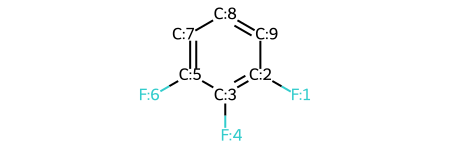

In [420]:
Chem.MolFromSmiles('[F:1][c:2]1[c:3]([F:4])[c:5]([F:6])[cH:7][cH:8][cH:9]1')

In [421]:
dict_borrylators = {}
for bohrylator_smiles in df['reagent_1_smiles'].unique():
    mol_borrylator = Chem.MolFromSmiles(bohrylator_smiles)
    mapped = False
    for atom in mol_borrylator.GetAtoms():
        if atom.GetAtomicNum() == 5 and not mapped:
            atom.SetAtomMapNum(1)
            mapped = True
    new_smiles = Chem.MolToSmiles(mol_borrylator)
    dict_borrylators[bohrylator_smiles] = new_smiles

dict_borrylators[0] = '[Ar:1]'

def add_mapnum_borrylators(smiles_bohr_):
    return dict_borrylators[smiles_bohr_]

In [422]:
df_bohrylators = pd.DataFrame(df['reagent_1_smiles'])
df_bohrylators['reagent_1_smiles'] = df_bohrylators['reagent_1_smiles'].apply(add_mapnum_borrylators)
df_bohrylators.fillna('[Ar:1]', inplace=True)

borrylators = list(set(list(df_bohrylators['reagent_1_smiles'].unique())))
                   
df_bohrylators_onehot = pd.DataFrame(columns= [('BOHR_' + b) for b in borrylators], data=np.zeros([len(df), len(borrylators)]))

for i in range(len(df_bohrylators_onehot)):
    bohrylator = df_bohrylators.loc[i, 'reagent_1_smiles']
    df_bohrylators_onehot.loc[i, 'BOHR_'+bohrylator] += 1

df_bohrylators_onehot

,BOHR_CC1(C)OB([B:1]2OC(C)(C)C(C)(C)O2)OC1(C)C,BOHR_CC1(C)O[BH:1]OC1(C)C,BOHR_CC1(C)OB(O[B:1]2OC(C)(C)C(C)(C)O2)OC1(C)C,BOHR_c1ccc2c(c1)O[BH:1]O2,BOHR_CC[Si](CC)(CC)[B:1]1OC(C)(C)C(C)(C)O1,BOHR_C1COB([B:1]2OCCO2)O1,BOHR_CC1CC(C)(C)OB([B:1]2OC(C)CC(C)(C)O2)O1,BOHR_Br[B:1](Br)Br
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
633,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
634,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
635,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
636,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## ALmost forgot: the ligands!

In [423]:
df['ligand_1_smiles'].value_counts()

ligand_1_smiles
N=1C=CC(=CC1C=2N=CC=C(C2)C(C)(C)C)C(C)(C)C                                                                        134
O=C1C=CC=2C=CC=C(C3=CN=C(C=C3)C=4N=CC=CC4)C2N1                                                                     71
N=1C=C(C(=C2C=CC3=C(N=CC(=C3C)C)C12)C)C                                                                            35
N=1C(OC)=CC(OC)=C2C=CC=CC12                                                                                        27
O=S(=O)([O-])CC=1C=NC(=CC1)C2=NC=C(C=C2)C.CCCC[N+](CCCC)(CCCC)CCCC                                                 26
O=C(NC1=CC=CC2=C1NC(=C2C)C)C=3C=NC(=CC3)C4=NC=CC=C4                                                                25
N=1C=CC=CC1N2B(NC=3C=CC=CC32)B4NC=5C=CC=CC5N4C6=NC=CC=C6                                                           23
N=1C=CC=C2C=CC=3C=CC(=NC3C12)C                                                                                     23
O(C1=CC=CC(=C1C=2C(OC)=CC=CC2P(C=3C=C(C=

Looks a bit too complicated, so we will just go with the one-hot encoding:

In [424]:
df_ligands = df[['ligand_1_smiles', 'ligand_2_smiles']]
df_ligands.fillna('Ar', inplace=True)

ligands = list(set(list(df_ligands['ligand_1_smiles'].unique())+ list(df_ligands['ligand_2_smiles'].unique())))

df_ligands_onehot = pd.DataFrame(columns= [('LIGAND_' + l) for l in ligands], data=np.zeros([len(df), len(ligands)]))

for i in range(len(df_ligands)):
    ligand1 = df_ligands.loc[i, 'ligand_1_smiles']
    ligand2 = df_ligands.loc[i, 'ligand_2_smiles']

    df_ligands_onehot.loc[i, 'LIGAND_'+ligand1] += 1
    df_ligands_onehot.loc[i, 'LIGAND_'+ligand2] += 1

df_ligands_onehot

/var/folders/xl/v8lcvy855_39wt1534xvs_hw0000gn/T/ipykernel_43035/2362369920.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ligands.fillna('Ar', inplace=True)


,LIGAND_O=S(=O)([O-])CC=1C=NC(=CC1)C2=NC=C(C=C2)C.CCCC[N+](CCCC)(CCCC)CCCC,LIGAND_N=1C=CC(=CC1C=2N=CC=C(C2)C(C)(C)C)C(C)(C)C,LIGAND_O=C(NC1=CC=CC2=C1NC(=C2C)C)C=3C=NC(=CC3)C4=NC=CC=C4,LIGAND_N=1C=C(C(=C2C=CC3=C(N=CC(=C3C)C)C12)C)C,LIGAND_N=1C=C(C=CC1C=2N=CC(=CC2)C)C,LIGAND_O=C(NC(C1=NC(CO1)C(C)C)C(C)CC)C,LIGAND_[Fe].CC(C)P([C]1[CH][CH][CH][CH]1)C(C)C.CC(C)P([C]2[CH][CH][CH][CH]2)C(C)C,LIGAND_O=C(C=CC1=CC=C(C=C1)C(F)(F)F)C=CC2=CC=C(C=C2)C(F)(F)F,LIGAND_O1C=2C=CC=3C=CC=CC3C2C4=C(OP1OC=5C=CC=6C=CC=CC6C5C7=C(O[Si](C(C)C)(C(C)C)C(C)C)C=CC=8C=CC=CC87)C=CC=9C=CC=CC94,LIGAND_N=1C=CC=C2C=CC=3C=CC(=NC3C12)C,...,LIGAND_O=C(NC(C1=NC(CC=2C=CC=CC2)C(O1)C3=CC=C(C=C3)C(F)(F)F)C(C)(C)C)C,LIGAND_N=1C=CC=C2C=CC=3C=CC=NC3C12,LIGAND_N=1C=CC(=CC1C=2N=CC=C(C2)C)C,LIGAND_O(C1=CC=CC(=C1C=2C(OC)=CC=CC2P(C=3C=C(C=C(C3)C)C)C=4C=C(C=C(C4)C)C)P(C=5C=C(C=C(C5)C)C)C=6C=C(C=C(C6)C)C)C,LIGAND_CC(C)(C)c1cc(c2nccc(c2)C3=CC(=CC=C3)C(C)(C)C)nc1,LIGAND_O=C(NC(C1=NC(CO1)CC(C)C)C(C)CC)C,LIGAND_O=C1C=CC=2C=CC=C(C3=CN=C(C=C3)C=4N=CC=CC4)C2N1,LIGAND_N#N,LIGAND_O=C(NCC=1C=NC(=CC1)C2=NC=CC=C2)NC3CCCCC3,LIGAND_FC(F)(F)C1OB(OC1)C=2C=CC=CC2C=3C=NC(=CC3)C4=NC=CC=C4
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
633,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
634,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
635,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
636,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [425]:
df_catalysts_onehot = pd.DataFrame(columns=[('CATALYST_' + cat) for cat in catalysts], data = np.zeros([len(df), len(catalysts)]))
df_catalysts = pd.DataFrame()

df_catalysts['catalyst_1_smiles'] = df['catalyst_1_smiles'].copy()
df_catalysts['catalyst_present'] = np.logical_not(df_catalysts['catalyst_1_smiles'].isnull())
df_catalysts['catalyst_1_smiles'] = df_catalysts['catalyst_1_smiles'].fillna(value=0)
df_catalysts['catalyst_1_smiles'] = df_catalysts['catalyst_1_smiles'].apply(replace_smiles)


for i, catalyst in enumerate(df_catalysts['catalyst_1_smiles']):
    df_catalysts_onehot.loc[i, 'CATALYST_' + catalyst] = 1

df_catalysts_onehot

,CATALYST_[O]1(C)[Ir:1]234([O](C)[Ir:1]1567[CH]-8CC[CH]7-[CH]6CC[CH]85)[CH]-9CC[CH]4-[CH]3CC[CH]92,CATALYST_Cc1cc(C)cc(C)c1[Ir:1](B1OC(C)(C)C(C)(C)O1)(B2OC(C)(C)C(C)(C)O2)B3OC(C)(C)C(C)(C)O3,CATALYST_[F][B-:1]([F])([F])[C]=1C=CC=CC1N2CCCCC2,CATALYST_[Ni:1]([C-1]1-N(C=CN1C=2C(=CC(=CC2C)C)C)C=3C(=CC(=CC3C)C)C)[C-1]4N(C=CN4C=5C(=CC(=CC5C)C)C)C=6C(=CC(=CC6C)C)C,CATALYST_[Rh:1](Cl)(C1=CCCCCC1)(C2=CCCCCC2)[Rh:1](Cl)(C3=CCCCCC3)C4=CCCCCC4,CATALYST_O1[Si](C)(C)[CH]2=[CH2][Pt+2:1]32(=[C]4N(C=CN4C5CCCCC5)C6CCCCC6)[CH2]=[CH]3[Si]1(C)C,CATALYST_C(#[N+][Pd:1][N+]#CC)C,CATALYST_[OH]1[Ir:1]234([OH][Ir:1]1567[CH]8CC[CH]7[CH]6CC[CH]85)[CH]9CC[CH]4[CH]3CC[CH]92,CATALYST_[N:1]#N,CATALYST_C=1C=C2[N]3=C(C1)C[P](C(C)C)(C(C)C)[Co+:1]3(C[Si](C)(C)C)[P](C2)(C(C)C)C(C)C,CATALYST_[F][B-:1]([F])([F])[C]=1C=CC=CC1N(CC)CC,CATALYST_O=C(C(C)(C)C)[O][Co+3:1]12([N]3=C(C[P]2(C(C)C)C(C)C)C=C(C)C=C3C[P]1(C(C)C)C(C)C)[O]C(C(C)(C)C)=O,CATALYST_[Co+3:1]12([B]3OC(C)(C)C(O3)(C)C)[N]=4C(=CC(=CC4C[P]1(C(C)C)C(C)C)C)C[P]2(C(C)C)C(C)C,CATALYST_[F][B-:1]([F])([F])[C]=1C=CC=CC1N2C(C)(C)CCCC2(C)C,CATALYST_CC(=O)O[Pd:1]OC(=O)C,CATALYST_[Cl]1[Ir+:1]234([Cl][Ir+:1]1567[CH]8CC[CH]7[CH]6CC[CH]85)[CH]9CC[CH]4[CH]3CC[CH]92,CATALYST_FC=1C(F)=C(F)C([B:1](C=2C(F)=C(F)C(F)=C(F)C2F)C=3C(F)=C(F)C(F)=C(F)C3F)=C(F)C1F
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
633,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
634,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
635,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
636,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [426]:
df['ligand_2_smiles'].value_counts()

ligand_2_smiles
N#N                                      10
O=C(NC1=CC=CC=C1C2=CN=CC=C2)NC3CCCCC3     8
Name: count, dtype: int64

In [427]:
df_clean = pd.concat([df_clean, df_bohrylators_onehot, df_solvents_semionehot, df_catalysts_onehot, df_ligands_onehot, df_bases, df_potassium, df_others], axis=1)
df_clean['reaction_id'] = df['rxn_id']
df_clean['new'] = df['new']

In [428]:
df_clean

,substrate_smiles_mapped,product_smiles_mapped,temperature_degC,reactivity_map,BOHR_CC1(C)OB([B:1]2OC(C)(C)C(C)(C)O2)OC1(C)C,BOHR_CC1(C)O[BH:1]OC1(C)C,BOHR_CC1(C)OB(O[B:1]2OC(C)(C)C(C)(C)O2)OC1(C)C,BOHR_c1ccc2c(c1)O[BH:1]O2,BOHR_CC[Si](CC)(CC)[B:1]1OC(C)(C)C(C)(C)O1,BOHR_C1COB([B:1]2OCCO2)O1,...,OTHER_OC(C)(C)C(O)(C)C,OTHER_O(C=1C=C(OC)C=C(OC)C1)C,OTHER_[K].O=S(=O)(O)OOS(=O)(=O)O,OTHER_O1BOC(C)(C)C1(C)C,OTHER_O(C)CCOC,OTHER_ClC(Cl)C(Cl)Cl,OTHER_[Na].O=S(=O)(O)C1=CC=C(C=C1)C,OTHER_[F-][B+3]([F-])([F-])[F-].CC[N+](CC)(CC)CC,reaction_id,new
0,[Br:1][c:2]1[cH:3][cH:4][c:5]([Br:6])[cH:7][cH...,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,100,{4: 1.0},1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,lit_pub_bo_222,False
1,[Br:1][c:2]1[cH:3][cH:4][c:5]2[nH:6][cH:7][cH:...,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,80,{4: 1.0},1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,lit_pub_bo_27,False
2,[Br:1][c:2]1[cH:3][cH:4][cH:5][c:6]([Br:7])[cH...,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,100,{4: 1.0},1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,lit_pub_bo_206,False
3,[Br:1][c:2]1[cH:3][cH:4][cH:5][cH:6][c:7]1[Br:8],[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,80,{5: 1.0},1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,lit_pub_bo_207,False
4,[Br:1][c:2]1[cH:3][cH:4][cH:5][s:6]1,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,100,{5: 1.0},1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,lit_pub_bo_216,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
633,[cH:1]1[cH:2][cH:3][c:4]2[o:5][cH:6][cH:7][c:8...,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,100,"{6: 0.7446808510638298, 7: 0.2553191489361702}",1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,lit_pub_bo_248,False
634,[cH:1]1[cH:2][cH:3][c:4]2[s:5][cH:6][cH:7][c:8...,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,100,"{7: 0.0909090909090909, 6: 0.9090909090909092}",1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,lit_pub_bo_247,False
635,[cH:1]1[cH:2][n:3][c:4]2[nH:5][cH:6][cH:7][c:8...,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,80,{7: 1.0},1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,lit_pub_bo_76,False
636,[cH:1]1[cH:2][n:3][nH:4][cH:5]1,[CH3:1][C:2]1([CH3:3])[O:4][B:5]([c:6]2[cH:7][...,80,{1: 1.0},1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,lit_pub_bo_70,False


In [429]:
df_clean.columns

Index(['substrate_smiles_mapped', 'product_smiles_mapped', 'temperature_degC',
       'reactivity_map', 'BOHR_CC1(C)OB([B:1]2OC(C)(C)C(C)(C)O2)OC1(C)C',
       'BOHR_CC1(C)O[BH:1]OC1(C)C',
       'BOHR_CC1(C)OB(O[B:1]2OC(C)(C)C(C)(C)O2)OC1(C)C',
       'BOHR_c1ccc2c(c1)O[BH:1]O2',
       'BOHR_CC[Si](CC)(CC)[B:1]1OC(C)(C)C(C)(C)O1',
       'BOHR_C1COB([B:1]2OCCO2)O1',
       ...
       'OTHER_OC(C)(C)C(O)(C)C', 'OTHER_O(C=1C=C(OC)C=C(OC)C1)C',
       'OTHER_[K].O=S(=O)(O)OOS(=O)(=O)O', 'OTHER_O1BOC(C)(C)C1(C)C',
       'OTHER_O(C)CCOC', 'OTHER_ClC(Cl)C(Cl)Cl',
       'OTHER_[Na].O=S(=O)(O)C1=CC=C(C=C1)C',
       'OTHER_[F-][B+3]([F-])([F-])[F-].CC[N+](CC)(CC)CC', 'reaction_id',
       'new'],
      dtype='object', length=115)

In [430]:
df['reagent_3_smiles'].value_counts()

reagent_3_smiles
[F-][B+3]([F-])([F-])[F-].CC[N+](CC)(CC)CC    27
OC(C)(C)C(O)(C)C                              23
N(CC)(CC)CC                                   19
[Na].O=S(=O)(O)C1=CC=C(C=C1)C                 15
NC(C)(C)C                                     14
N=1C=CC=CC1                                   11
NC                                            10
N#N                                           10
[K].O=P(O)(O)O                                 1
Name: count, dtype: int64

In [431]:
print(f'The current number of features is: {len(df_clean.columns)}')

The current number of features is: 115


In [432]:
df_clean.to_csv('FULLY_cleaned_ONE_HOT_ENCODED.csv')

In [433]:
print('ALL CATALYST COLUMNS ARE:\n')
for col in df_clean.columns:
    if 'CATALYST_' in col:
        print(col+'\n')

ALL CATALYST COLUMNS ARE:

CATALYST_[O]1(C)[Ir:1]234([O](C)[Ir:1]1567[CH]-8CC[CH]7-[CH]6CC[CH]85)[CH]-9CC[CH]4-[CH]3CC[CH]92

CATALYST_Cc1cc(C)cc(C)c1[Ir:1](B1OC(C)(C)C(C)(C)O1)(B2OC(C)(C)C(C)(C)O2)B3OC(C)(C)C(C)(C)O3

CATALYST_[F][B-:1]([F])([F])[C]=1C=CC=CC1N2CCCCC2

CATALYST_[Ni:1]([C-1]1-N(C=CN1C=2C(=CC(=CC2C)C)C)C=3C(=CC(=CC3C)C)C)[C-1]4N(C=CN4C=5C(=CC(=CC5C)C)C)C=6C(=CC(=CC6C)C)C

CATALYST_[Rh:1](Cl)(C1=CCCCCC1)(C2=CCCCCC2)[Rh:1](Cl)(C3=CCCCCC3)C4=CCCCCC4

CATALYST_O1[Si](C)(C)[CH]2=[CH2][Pt+2:1]32(=[C]4N(C=CN4C5CCCCC5)C6CCCCC6)[CH2]=[CH]3[Si]1(C)C

CATALYST_C(#[N+][Pd:1][N+]#CC)C

CATALYST_[OH]1[Ir:1]234([OH][Ir:1]1567[CH]8CC[CH]7[CH]6CC[CH]85)[CH]9CC[CH]4[CH]3CC[CH]92

CATALYST_[N:1]#N

CATALYST_C=1C=C2[N]3=C(C1)C[P](C(C)C)(C(C)C)[Co+:1]3(C[Si](C)(C)C)[P](C2)(C(C)C)C(C)C

CATALYST_[F][B-:1]([F])([F])[C]=1C=CC=CC1N(CC)CC

CATALYST_O=C(C(C)(C)C)[O][Co+3:1]12([N]3=C(C[P]2(C(C)C)C(C)C)C=C(C)C=C3C[P]1(C(C)C)C(C)C)[O]C(C(C)(C)C)=O

CATALYST_[Co+3:1]12([B]3OC(C)(C)C(O3)(C)C)[N]=4C(=CC

In [434]:
print('ALL LIGAND COLUMNS ARE:\n')
for col in df_clean.columns:
    if 'LIGAND_' in col:
        print(col+'\n')

ALL LIGAND COLUMNS ARE:

LIGAND_O=S(=O)([O-])CC=1C=NC(=CC1)C2=NC=C(C=C2)C.CCCC[N+](CCCC)(CCCC)CCCC

LIGAND_N=1C=CC(=CC1C=2N=CC=C(C2)C(C)(C)C)C(C)(C)C

LIGAND_O=C(NC1=CC=CC2=C1NC(=C2C)C)C=3C=NC(=CC3)C4=NC=CC=C4

LIGAND_N=1C=C(C(=C2C=CC3=C(N=CC(=C3C)C)C12)C)C

LIGAND_N=1C=C(C=CC1C=2N=CC(=CC2)C)C

LIGAND_O=C(NC(C1=NC(CO1)C(C)C)C(C)CC)C

LIGAND_[Fe].CC(C)P([C]1[CH][CH][CH][CH]1)C(C)C.CC(C)P([C]2[CH][CH][CH][CH]2)C(C)C

LIGAND_O=C(C=CC1=CC=C(C=C1)C(F)(F)F)C=CC2=CC=C(C=C2)C(F)(F)F

LIGAND_O1C=2C=CC=3C=CC=CC3C2C4=C(OP1OC=5C=CC=6C=CC=CC6C5C7=C(O[Si](C(C)C)(C(C)C)C(C)C)C=CC=8C=CC=CC87)C=CC=9C=CC=CC94

LIGAND_N=1C=CC=C2C=CC=3C=CC(=NC3C12)C

LIGAND_N1=CC(=CC=2C=CC=3C=C(C=NC3C12)C=4C=C(C=C(C4)C)C)C5=CC(=CC(=C5)C)C

LIGAND_O=C(NC1=CC=CC=C1C2=CN=CC=C2)NC3CCCCC3

LIGAND_O=C(NC1=CC=C(C=C1)C(F)(F)F)NC=2C=CC=CC2C=3C=NC(=CC3)C4=NC=CC=C4

LIGAND_Ar

LIGAND_N1=CC=CC2=CC=CC(N)=C12

LIGAND_N=1C=CC=CC1C=NN(CC=2C=CC=CC2)CC=3C=CC=CC3

LIGAND_O=C(NC=1C=CC=CC1C=2C=NC(=CC2)C3=NC=CC=C3)NC4CCCCC4

LIGAND_CC(C)(C)c1c

In [435]:
print('ALL BASE COLUMNS ARE:\n')
for col in df_clean.columns:
    if 'BASE_' in col:
        print(col+'\n')

ALL BASE COLUMNS ARE:

BASE_[K].O=P(O)(O)O

BASE_[K].OC(C)(C)C

BASE_N=1C(=CC=CC1C)C

BASE_NC(C)(C)C

BASE_NC

BASE_[K].O=C(O)O

BASE_N(CC)(CC)CC

BASE_N=1C=CC=CC1



In [436]:
print('ALL POTASSIUM/SODIUM COLUMNS ARE:\n')
for col in df_clean.columns:
    if 'NaK_' in col:
        print(col+'\n')

ALL POTASSIUM/SODIUM COLUMNS ARE:

NaK_[K].O=P(O)(O)O

NaK_[K].OC(C)(C)C

NaK_[K].O=C(O)O

NaK_[K].O=S(=O)(O)OOS(=O)(=O)O

NaK_[Na].O=S(=O)(O)C1=CC=C(C=C1)C



In [437]:
print('ALL OTHER COLUMNS ARE:\n')
for col in df_clean.columns:
    if 'OTHER_' in col:
        print(col+'\n')

ALL OTHER COLUMNS ARE:

OTHER_BrCBr

OTHER_C=12C(=C3C(=C4C1CCCC4)CCCC3)CCCC2

OTHER_C=1C(=CC(=CC1C)C)C

OTHER_C1=CC2C=CC1C2

OTHER_NC(C)(C)C

OTHER_NC

OTHER_O=C(O)C

OTHER_OC(C)(C)C(O)(C)C

OTHER_O(C=1C=C(OC)C=C(OC)C1)C

OTHER_[K].O=S(=O)(O)OOS(=O)(=O)O

OTHER_O1BOC(C)(C)C1(C)C

OTHER_O(C)CCOC

OTHER_ClC(Cl)C(Cl)Cl

OTHER_[Na].O=S(=O)(O)C1=CC=C(C=C1)C

OTHER_[F-][B+3]([F-])([F-])[F-].CC[N+](CC)(CC)CC



In [438]:
df_new = pd.read_csv('ChemAI-papers.csv')
#df_new.drop(columns = )
df_new.loc[0, 'substrate_smiles_mapped']

'[F:1][c:2]1[c:3]([F:4])[c:5]([F:6])[cH:7][cH:8][cH:9]1'

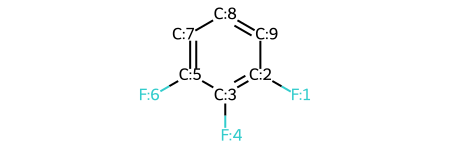

In [439]:
mol = Chem.MolFromSmiles(df_new.loc[0, 'substrate_smiles_mapped'])
mol

In [440]:
list(df.columns)

['rxn_id',
 'substrate_smiles',
 'substrate_smiles_mapped',
 'temperature_degC',
 'solvent_1_smiles',
 'solvent_1_fraction',
 'solvent_2_smiles',
 'solvent_2_fraction',
 'catalyst_1_smiles',
 'catalyst_2_smiles',
 'ligand_1_smiles',
 'ligand_2_smiles',
 'additive_1_smiles',
 'reagent_1_smiles',
 'reagent_2_smiles',
 'reagent_3_smiles',
 'reagent_4_smiles',
 'product_smiles',
 'product_smiles_mapped',
 'site',
 'yield',
 'source_DOI',
 'new',
 'reactivity_map']

In [441]:
list(df_new.columns)

['paper',
 'rxn_id',
 'substrate_smiles',
 'substrate_smiles_mapped',
 'temperature_degC',
 'solvent_1_smiles',
 'solvent_1_fraction',
 'solvent_2_smiles',
 'solvent_2_fraction',
 'catalyst_1_smiles',
 'catalyst_2_smiles',
 'ligand_1_smiles',
 'ligand_2_smiles',
 'additive_1_smiles',
 'reagent_1_smiles',
 'reagent_2_smiles',
 'reagent_3_smiles',
 'reagent_4_smiles',
 'total_yield',
 'product_smiles',
 'product_smiles_mapped',
 'site',
 'yield',
 'regio_fraction',
 'source_DOI']